# Which advisories can hurt production? Scan every one, or ask the graph first

Your Python services depend on hundreds of packages, and thousands of public advisories exist for PyPI packages, but most of them never reach your production code. This notebook uses a Cypher query over the dependency graph to keep only the advisories that a production service reaches, asks a model typed questions about them with `sem_decide`, and measures what each step saves in requests, cost and time.

![Five stages: time, cost and quality](gfql_semantic_supply_chain_chart.png)

*The chart comes from the run below. The numbers are simulated: the notebook answers with a calibrated mock model. See "What is real and what is simulated".*

| you will see | where |
|---|---|
| Cypher, `sem_decide`, a plan and a trace in one cell | **The pipeline in one cell** |
| what is real and what is simulated | **What is real and what is simulated** |
| the lockfile, the advisories, the labels and the simulator | **The data, the labels and the simulated model** |
| five stages with tables | **Stages 1 to 3**, **Stages 4 and 5** |
| the chart and a graph to plot | **The chart**, **Blast radius** |
| how to measure a live model (opt in, gated) | **Measure a live model** |

**Setup.** The first run downloads the public OSV archive (38 MB) into `/tmp/osv-pypi-cache`, so it needs network access. The helper module `supply_chain_helpers.py` holds the lockfile reader, the OSV download and parse, the labels, the simulator, the stage runners and the chart code. The notebook expects it and `gfql_semantic_supply_chain_lockfile.json` in the same folder (`demos/gfql/`): start Jupyter there, or add that folder to `sys.path`. The Appendix shows its source.

| environment variable | effect |
|---|---|
| `DEMO_LIVE=1` | use a live model (needs keys and spends money; see the end) |
| `BUILD_LOCKFILE=1` | rebuild the lockfile from the PyPI JSON API before the run (see "The data") |

*Advisory text: [OSV](https://osv.dev) PyPI database, which aggregates the GitHub Advisory Database and the PyPA Advisory Database (both [CC-BY 4.0](https://creativecommons.org/licenses/by/4.0/)). OSV code is Apache-2.0. Dependency data: the public PyPI JSON API.*

In [1]:
import polars as pl

import supply_chain_helpers as h

h.init()    # read the lockfile, download OSV (once), join, label, build the graph

from graphistry import e_forward, n
from graphistry.compute.semantic import (
    MemorySemanticCache,
    bind_providers,
    explain_sem_decide,
    semantic_summary,
    semantic_trace,
    semantic_verdicts,
)
from supply_chain_helpers import (
    BUDGET,
    EVIDENCE,
    PARALLEL,
    QUESTIONS,
    decisions_provider,
    g,
    session_for,
    show,
)

print("mode:", "LIVE model (opt in)" if h.DEMO_LIVE else "simulated model ($0, no key)")

snapshot 2025-05-22 | 6 services | 214 packages | 358 package-to-package edges (1 requirement without a pinned release is left out)


Google OSV PyPI database (full download) | 9,553 advisory records kept
dropped because the text states its own score or severity: 440 of 9,993 records with a CVSS v3 vector (this removes advisories that quote a severity, so the kept set is a selection)
5,806 advisories after merging aliases and identical texts (10 merged) | 300 hit a package in the lockfile
mode: simulated model ($0, no key)


## The pipeline in one cell

**Input:** a Cypher query on the dependency graph keeps the advisories that a production service reaches through its dependencies (1 to 8 hops). The `RETURN` carries the text that the model reads, because the advisory nodes hold it, so `.sem_decide` runs on the query result with no glue. **Config:** three typed questions, a provider, a cost cap and a probability limit (`min_p`). **Output:** one verdict for each advisory, a plan before the run and a trace after it. The provider is simulated here, so the cell costs $0.

In Cypher, `(s:service)` and `[:depends_on*1..8]` read the `type` column of the nodes and the edges. The pattern is written from the advisory back to the service, because the Polars engine runs a variable-length edge at the end of a pattern but not one in the middle. The GFQL chain below runs on Polars too. This cell leaves `dedupe` on, its default: a repeated text is asked once. The five stages below pass `dedupe=False`, so that each stage asks about every row, as a plain loop does.

In [2]:
# 1. Input: narrow the graph with Cypher
candidates = g.gfql(
    """
    MATCH (a:advisory)<-[:has_advisory]-(p:package)
          <-[:depends_on*1..8]-(s:service {tier: 'prod'})
    RETURN DISTINCT a.id AS adv_id,
                    a.package AS package,
                    a.summary AS summary,
                    a.details AS details
    """,
    engine="polars",
)

# 2. Config: typed questions (QUESTIONS), a provider and guardrails
provider = decisions_provider(session_for())  # simulated unless DEMO_LIVE=1
args = dict(
    questions=QUESTIONS,
    task_id="advisory-triage",
    evidence_cols=EVIDENCE,
    id_col="adv_id",
    max_concurrency=PARALLEL,
    budget=BUDGET,
    require_probabilities=True,
    min_p=0.85,
)

# 3. Run: a plan (no request), then the decisions on the Cypher result, under a trace
plan = explain_sem_decide(candidates._nodes, provider=provider, **args)
cache = MemorySemanticCache()
with bind_providers({"triage": provider}, cache=cache), semantic_trace() as runs:
    triaged = candidates.sem_decide(provider="triage", **args)

# 4. Output: status counts that never hide an unanswered row, the verdicts, and the trace
verdict = semantic_verdicts(triaged._nodes, "remediation_urgency", positive="patch_now")
show(semantic_summary(triaged._nodes))
show(verdict.value_counts().rename("advisories").to_frame().T)
print(
    f"plan: {plan['planned_calls']:,} calls for {plan['active_rows']:,} advisories | "
    f"run: {runs[0]['provider_calls']:,} calls, billed ${runs[0]['billed_cost_usd']:.2f}"
)

*Simulated cost/latency model on real OSV PyPI advisories*

,ok,uncertain,error,skipped,unanswered,unanswered_pct
question,,,,,,
pre_auth_remote,176,45,0,0,45,20.36
exploit_vector,145,76,0,0,76,34.39
remediation_urgency,144,77,0,0,77,34.84


*Simulated cost/latency model on real OSV PyPI advisories*

,yes,uncertain,no,error,skipped
advisories,77,77,67,0,0


plan: 221 calls for 221 advisories | run: 221 calls, billed $0.30


In [3]:
# The same query as a GFQL chain (Python objects), on the Polars engine
reach_chain = [
    n({"tier": "prod"}),
    e_forward({"type": "depends_on"}, min_hops=1, max_hops=8),
    n({"type": "package"}),
    e_forward({"type": "has_advisory"}),
    n({"type": "advisory"}),
]
reached = g.gfql(reach_chain, engine="polars")._nodes
chain_ids = reached.filter(pl.col("type") == "advisory")["id"]
hero_ids = set(candidates._nodes["adv_id"])
assert set(chain_ids) == hero_ids, "Cypher and the chain must agree"
print(f"{len(chain_ids):,} advisories from the chain: the same rows as the Cypher query")

221 advisories from the chain: the same rows as the Cypher query


`yes` is an advisory that the model calls `patch_now` with a probability of at least 0.85. `uncertain` goes to a review queue. An `error` or `skipped` row is never counted as `no`. The rest of the notebook builds this cell up in five stages and measures each one.

## What is real and what is simulated

The advisories, the package versions, the package-to-package edges and the GFQL queries are **real**. The six services are an example. The default run sends **no request to a model**, uses **no API key** and costs **$0**. A *simulated* model answers the questions. Its cost, time and accuracy come from stated assumptions, not from a live benchmark. Every result table and chart says "simulated". Set `DEMO_LIVE=1` to measure a live model (see the end of the notebook).

> **Question.** Which advisories reach a production service, how fast must we patch each one, and which ones need a human to decide?

## The data, the labels and the simulated model

## Setup

One setup cell loads everything. The first run downloads the public OSV archive (38 MB) into `/tmp/osv-pypi-cache`, so it needs network access. The helper module
`supply_chain_helpers.py` holds the lockfile reader, the OSV download and parse, the labels, the simulator and the chart code. The Appendix at the end shows its source. The notebook
expects `supply_chain_helpers.py` and `gfql_semantic_supply_chain_lockfile.json` in the same folder (`demos/gfql/`): start Jupyter there, or add that folder to `sys.path`.

| environment variable | effect |
|---|---|
| `DEMO_LIVE=1` | use a live model (needs keys and spends money; see the end) |
| `BUILD_LOCKFILE=1` | rebuild the lockfile from the PyPI JSON API before the run (see "The dependency graph") |

**The OSV advisories.** The helper `load_osv` reads the OSV PyPI archive from `/tmp/osv-pypi-cache`, or downloads it from Google (38 MB) into that
directory first. The notebook commits no dataset file. If the download fails and the cache is empty, it stops with an
error that names the URL and the cache path. The summary and the chart name the data source.

Each advisory keeps the text a human would read (`summary` and `details`), the packages and versions it affects, and
its CVSS v3 vector. **The vector is the held-out ground truth.** The prompts never contain it. The notebook drops
advisories without a CVSS v3 vector, withdrawn advisories, malware reports, and advisories whose own text mentions a CVSS
score, a severity, a risk rating or a score (that text would show the answer to the model). The rule is a keyword filter, so
it can miss an unusual phrase. This last rule removes a small, non-random
part of the data. The run prints how many records it removes. An advisory that has both a CVE and a GHSA record
counts once.

**The join.** An advisory hits a package when the version in the lockfile is in the advisory's affected versions. The join uses the
`versions` list that OSV publishes, and falls back to the version ranges. The OSV data is from 2026, but the lockfile is
from 2025. The join therefore finds the advisories that affect the locked versions, **including advisories that were
published after the lockfile snapshot**.

**The graph.** The graph has three node types and two edge types:

- nodes: `service` (with its `tier`), `package` (with the locked `version`) and `advisory`
- edges: `depends_on` (a service or package needs a package) and `has_advisory` (a package has an advisory that hits the locked version)

**Three questions.** The model reads one advisory at a time: the package name, the summary and the first 1,200 characters of the details.
It answers three typed questions:

| question | kind | answers |
|---|---|---|
| `pre_auth_remote` | `predicate` | can an unauthenticated remote attacker trigger this without local access? |
| `exploit_vector` | `choice` | `network_rce`, `injection_or_traversal`, `dos_only` or `local_or_build_only` |
| `remediation_urgency` | `score` | `defer`, `schedule` or `patch_now` |

The held-out answers come from the CVSS v3 vector of each advisory. This is an objective but **coarse** proxy for
what an analyst decides:

- `pre_auth_remote`: attack vector is network (`AV:N`) and no privileges are needed (`PR:N`)
- `exploit_vector`: local or physical attack vector gives `local_or_build_only`; an impact on availability only gives `dos_only`;
  a network attack with high confidentiality and integrity impact gives `network_rce`; the rest give `injection_or_traversal`
- `remediation_urgency`: the CVSS base score is 7.0 or more for `patch_now`, 4.0 or more for `schedule`, else `defer`

The task has a *graph* part too: only an advisory that a production service reaches needs a patch. One advisory text
cannot show that. The positive class is therefore `patch_now` **and** reachable from a production service.

**Simulated model.** The default run answers with a *simulated* model. It does **not read** the advisory text. It looks up the held-out
label of the advisory and corrupts it. For each advisory and question it replays one fixed random draw, so every stage
sees the same answers and only the pipeline changes.

- The model is **calibrated by construction**. For each answer it holds a confidence `p`. It is right with probability
  `p`. A reported `p = 0.9` is right 90% of the time. When it is wrong, it picks another answer at random.
  Because `p` does not depend on the text, any gain from `min_p` below is a property of this simulator. A real model
  can be less calibrated, and you must measure it (see the live mode).
- Token counts come from the real request text (four characters per token). Prices and latency are assumptions.

**None of these numbers is measured.** They show how the stages combine. They do not rank a real model.

In [4]:
h.data_summary()

,service,tier,direct packages,examples
0,billing-svc,prod,7,"celery, cryptography, django, pydantic, redis"
1,ci-tools,ci,7,"pytest, pyyaml, requests, setuptools, tox"
2,dev-notebooks,dev,7,"ipython, jupyterlab, matplotlib, nbconvert, notebook"
3,docs-site,docs,6,"docutils, jinja2, mkdocs, pygments, requests"
4,ml-worker,prod,8,"boto3, mlflow, numpy, pandas, pillow"
5,prod-api,prod,10,"aiohttp, cryptography, flask, gunicorn, pillow"


,adv_id,package,summary
0,adv:GHSA-22fp-mf44-f2mq,youtube-dl,youtube-dl vulnerable to file system modification and RCE through ...
1,adv:GHSA-22gh-3r9q-xf38,mitmproxy,Lacking Protection against HTTP Request Smuggling in mitmproxy
2,adv:GHSA-22hf-vx2v-gjff,apache-airflow,Apache Airflow exposes deferred trigger kwargs in task-instance AP...


520 nodes | 704 edges


,nodes,edges
type,,
advisory,300.0,NaN
package,214.0,NaN
service,6.0,NaN
depends_on,NaN,403.0
has_advisory,NaN,301.0


5,806 advisories | 221 reach a production service | 133 of those need `patch_now`


,exploit_vector,remediation_urgency
defer,0,319
dos_only,956,0
injection_or_traversal,2535,0
local_or_build_only,963,0
network_rce,1352,0
patch_now,0,3046
schedule,0,2441


,assumption,value
0,model confidence p (mean),"pre_auth_remote 0.89, exploit_vector 0.86, remediation_urgency 0.86"
1,chat latency for one request,0.9 s
2,decisions latency for one request,1.2 s + 0.15 s for each question
3,"parallel requests, stages 1 to 3",1 (one request at a time)
4,"parallel requests, stages 4 and 5",8
5,price per million tokens (input / output),$2.5 / $10.0


## Stages 1 to 3: ask about everything, join, or follow the graph

Each stage asks the same three questions with the chat provider, one request at a time, with `dedupe=False`, as a plain loop over a chat API does. The tables show `rows` (all rows of the stage) and `asked` (rows that the model answered).

1. **Naive scan.** Every advisory. Most advisories do not reach production, and the model cannot know that: one advisory text says nothing about your graph. A table splits what the naive scan flags as `patch_now`.
2. **Package and version join (no graph).** A plain table join keeps the advisories that affect a locked version of a package that the repository uses. A package scanner does this. It is a fair baseline: it uses no graph, and it does not know which services use which package.
3. **GFQL reachability.** The graph query of the hero cell. The join cannot tell which of these advisories matter to **production**. The query starts at services of tier `prod`, follows `depends_on` edges for 1 to 8 hops, keeps packages, follows `has_advisory` and keeps advisories. It runs in Polars and does not call a model. (GFQL can also run the version join if you store the match as an edge attribute. This notebook does the join in plain Python, so that the comparison between stages 2 and 3 shows only what the graph adds.)

In [5]:
h.stage1()
h.stage2()

rows asked: 5,806 of 5,806 | local run time 4.8 s


*Simulated cost/latency model on real OSV PyPI advisories*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,precision,recall,errors
0,5806,5806,17418,14.42,15676.2,2847,113,0.04,0.85,0


*Simulated cost/latency model on real OSV PyPI advisories*

,advisories flagged by the naive scan
right: reaches production and needs patch_now,113
"needs patch_now, but no production service reaches it",2511
model mistake: does not need patch_now,223


5,806 advisories -> 300 after the join (19x fewer rows)


*Simulated cost/latency model on real OSV PyPI advisories*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,precision,recall,errors
0,300,300,900,0.838,810.0,155,113,0.729,0.85,0


In [6]:
h.stage3()

GFQL: 300 -> 221 advisories in 57 ms | 79 advisories only reach ci, dev or docs packages


,step,advisories left,removed by,patch_now and reachable kept
0,all advisories,5806,,133
1,package and version join,300,plain table join,133
2,GFQL reachability,221,"GFQL on polars, 57 ms (median of 5)",133


*Simulated cost/latency model on real OSV PyPI advisories*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,precision,recall,errors
0,221,221,663,0.591,596.757,124,113,0.911,0.85,0


## Stages 4 and 5: one call for three questions, then calibrated answers

4. **Three questions in one call, eight calls at once.** `OpenAIDecisionsProvider` asks all three questions about an advisory in one request and shares the advisory text. The notebook runs 8 requests at a time (`max_concurrency=8`), and `budget={"max_cost_usd": ...}` stops the run before the estimated cost passes the cap. The second table compares ways to send the same rows: concurrency, the shared call, and packing 8 rows per request (`rows_per_request=8`). Packing cuts requests and latency. It does not cut tokens, and it gives up the sharing across questions.
5. **`min_p` and `sem_map`.** `require_probabilities=True` accepts an answer only when the provider measured its probability, and `min_p=0.85` turns a lower one into `uncertain`, which goes to the review queue instead of a guess. `sem_map` then writes one fix note for each advisory that is `patch_now` or `uncertain`. Its evidence holds the locked version and the first fixed version from the advisory. The notes run 8 at a time and are capped by request count, because a `sem_map` call has no cost estimate here. It passes `dedupe=False`, like stages 1 to 4, so each row gets its own request.

**What to read in the next cells.** The accuracy table scores each question against the CVSS-based answer. In the simulated run `min_p` raises the accuracy of the accepted answers by construction, because the simulated confidence is calibrated. The `min_p` replay reads any threshold off the probabilities of stage 4: a higher `min_p` raises precision and sends more advisories to the review queue. With the simulated model that trend is a property of the simulator. With a live model it is a measurement.

In [7]:
h.stage4()
h.stage5()

probability kinds: {'native_decision': 221}


*Simulated cost/latency model on real OSV PyPI advisories*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,precision,recall,errors
0,221,221,221,0.299,45.639,124,113,0.911,0.85,0


*Simulated cost/latency model on real OSV PyPI advisories*

,how the same rows are sent,requests,cost_usd,seconds
0,"chat, 1 question per request, 1 at a time (stage 3)",663,0.591,596.700
1,"chat, 1 question per request, 8 at once",663,0.591,74.587
2,"3 questions per request, 8 at once (stage 4)",221,0.299,45.581
3,"8 rows packed per request, 8 at once",28,0.565,16.631


patch_now: 77 | review queue: 77 | notes: {'ok': 154} | sem_map cost $0.1086


*Simulated cost/latency model on real OSV PyPI advisories*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,precision,recall,errors,uncertain_pct
0,221,221,375,0.408,62.964,77,74,0.961,0.556,0,34.842


In [8]:
h.diagnostics()

*Simulated cost/latency model on real OSV PyPI advisories*

,question,kind,stage 4 accuracy,stage 4 answered,stage 5 accuracy,stage 5 answered
0,pre_auth_remote,predicate,0.923,221,0.955,176
1,exploit_vector,choice,0.900,221,0.938,145
2,remediation_urgency,score,0.837,221,0.910,144


*Simulated cost/latency model on real OSV PyPI advisories*

,min_p,patch_now,precision,recall,review queue
0,0.50,124,0.911,0.850,0%
1,0.70,118,0.915,0.812,5%
2,0.80,94,0.947,0.669,22%
3,0.85,77,0.961,0.556,35%
4,0.90,46,0.978,0.338,61%
5,0.95,23,1.000,0.173,83%


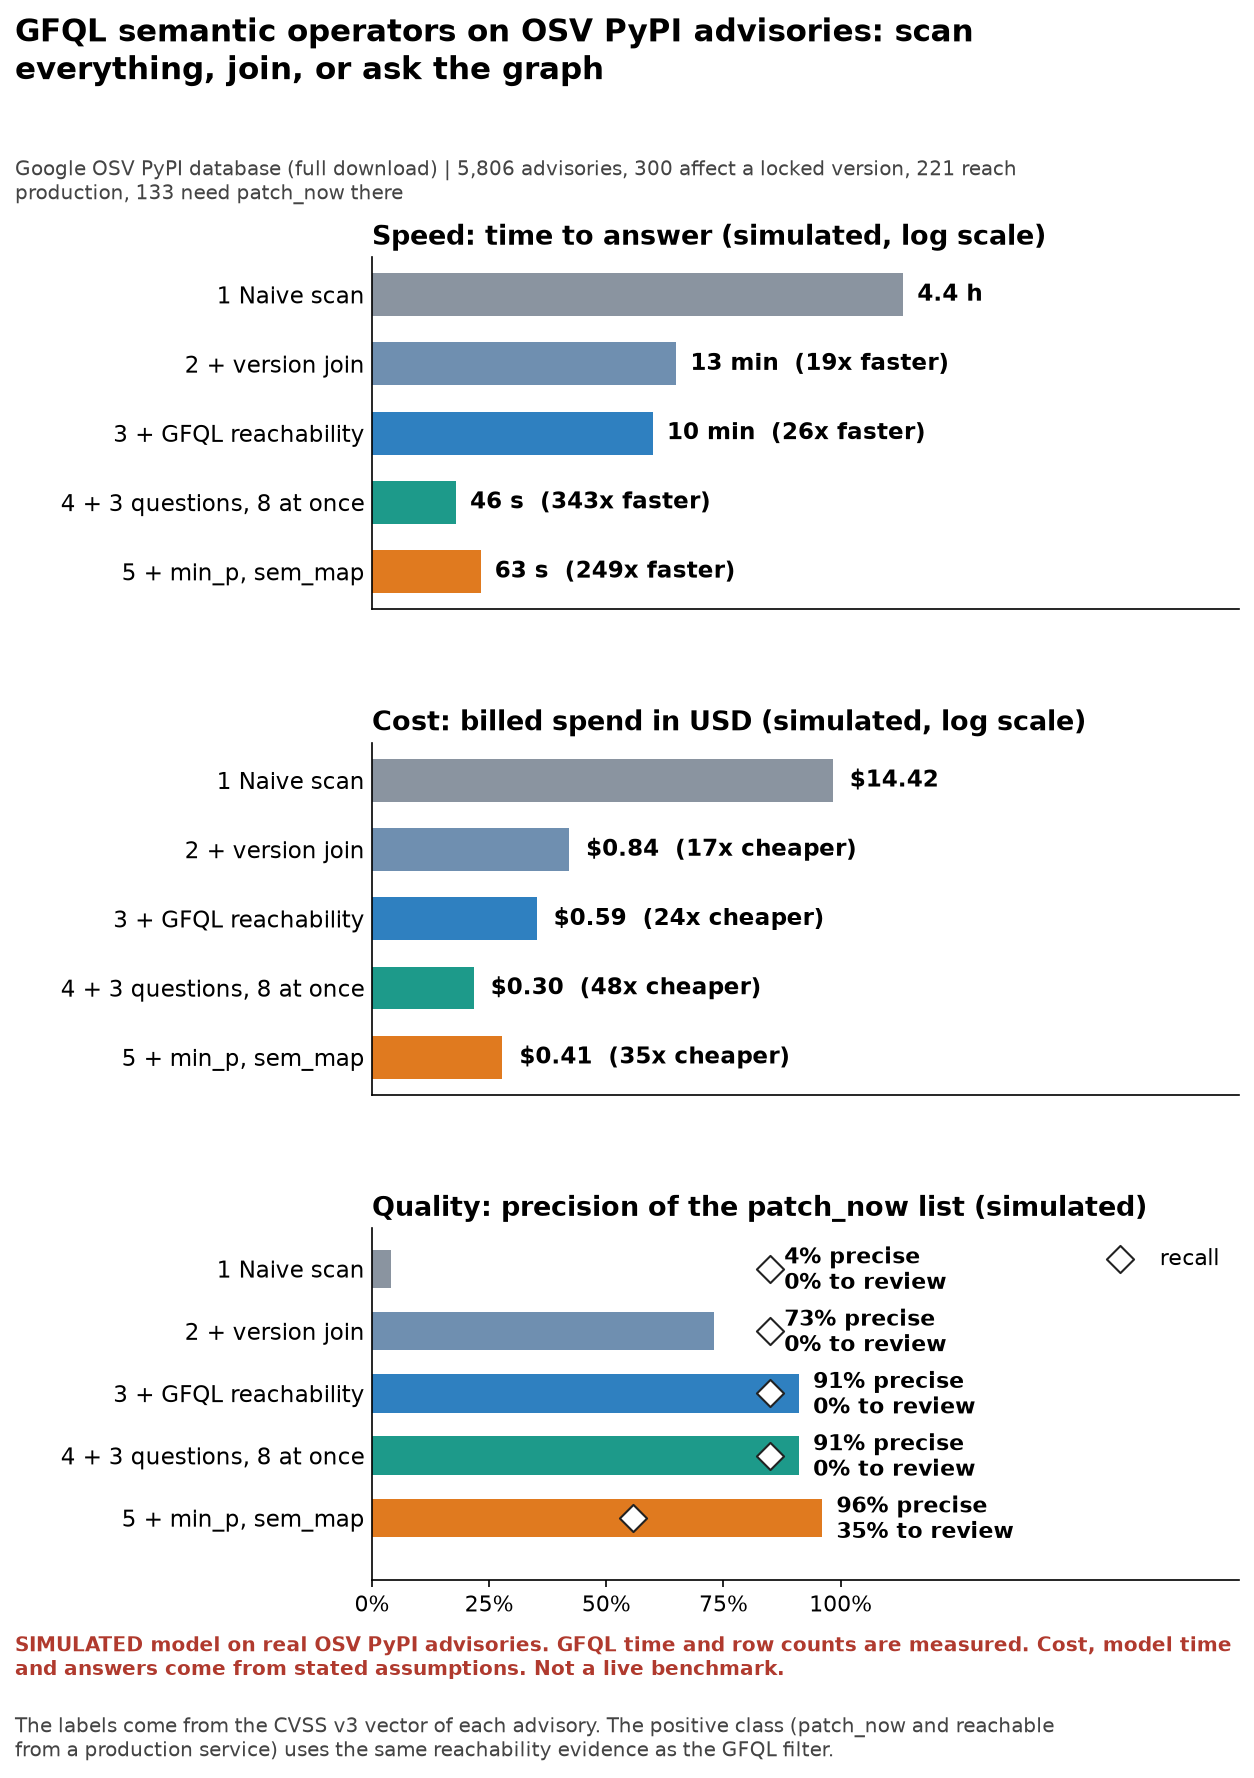

saved gfql_semantic_supply_chain_chart.png


In [9]:
h.chart()

## The chart

The chart above shows time, model spend and the precision of the `patch_now` list for the five stages. The time and cost axes are logarithmic. Stage 1 is a deliberately plain baseline: one call at a time, no filter. The simulator sets the latency of a call, so the time gains are modeled and not measured. The join does most of the row cut, and GFQL then removes the advisories that no production service reaches.

## Blast radius: walk back up the graph

A second GFQL query goes the other way. It starts at the advisories that need action (`patch_now` or `uncertain`), follows `has_advisory` edges back to packages, follows `depends_on` edges back up the dependency chains and stops at production services. The result is the exact set of packages and services at risk.

In [10]:
h.blast_radius()

reverse query: 54 ms | 190 nodes, 202 edges


preview only: set DEMO_PLOT=1 after graphistry.register(...) to open the graph


,name,tier
0,billing-svc,prod
1,ml-worker,prod
2,prod-api,prod


*Simulated cost/latency model on real OSV PyPI advisories*

,adv_id,package,verdict,remediation_urgency__p,prod_services_exposed,fix_note
0,adv:PYSEC-2026-1996,urllib3,uncertain,0.829,3,Upgrade urllib3 2.4.0 to 2.6.3 or later. Decompression-bomb safegu...
1,adv:GHSA-qccp-gfcp-xxvc,urllib3,uncertain,0.782,3,Upgrade urllib3 2.4.0 to 2.7.0 or later. urllib3: Sensitive header...
2,adv:PYSEC-2026-2252,pillow,flagged,0.979,2,Upgrade pillow 11.2.1 to 12.2.0 or later.
3,adv:GHSA-xg8h-j46f-w952,pillow,flagged,0.977,2,Upgrade pillow 11.2.1 to 11.3.0 or later. Pillow vulnerability can...
4,adv:PYSEC-2026-4326,pillow,flagged,0.975,2,Upgrade pillow 11.2.1 to 13.0.0 or later.
5,adv:GHSA-537c-gmf6-5ccf,cryptography,flagged,0.973,2,Upgrade cryptography 45.0.2 to 48.0.1 or later. Vulnerable OpenSSL...
6,adv:GHSA-9hw9-ch79-4vh6,pillow,flagged,0.971,2,Upgrade pillow 11.2.1 to 12.3.0 or later. Pillow: Controlled heap ...
7,adv:PYSEC-2026-4331,pillow,flagged,0.959,2,Upgrade pillow 11.2.1 to 13.0.0 or later.


*Simulated cost/latency model on real OSV PyPI advisories*

,adv_id,package,remediation_urgency__p,summary
35,adv:GHSA-82w8-qh3p-5jfq,starlette,0.850,Starlette: request.form() limits silently ignored for application/...
61,adv:GHSA-gqvg-gmmx-x4hm,mlflow,0.849,MLFLOW_ALLOW_PICKLE_DESERIALIZATION=False safety control bypassed ...
217,adv:PYSEC-2026-45,django,0.848,
207,adv:PYSEC-2026-4367,aiohttp,0.847,
209,adv:PYSEC-2026-4369,aiohttp,0.843,


In [11]:
h.summary()

Simulated cost/latency model on real OSV PyPI advisories | Google OSV PyPI database (full download)
Rows: 5,806 advisories -> 300 after the plain join -> 221 after GFQL reachability (57 ms).
The join does most of the row cut. GFQL removes the 79 advisories that no production service reaches, and keeps all 133 patch_now advisories that do.
Precision of the patch_now list: naive 4%, join 73%, GFQL 91%, with min_p 96%. Recall with min_p: 56%; 35% of reachable advisories go to the review queue.
Requests: 17,418 -> 900 -> 663 -> 221 (3 questions per call) -> 375 with 154 fix notes.
Cost: $14.42 -> $0.84 -> $0.59 -> $0.30 -> $0.41. Time: 4.4 h -> 13 min -> 10 min -> 46 s -> 63 s.


## Measure a live model (opt in)

Set `DEMO_LIVE=1` and restart the notebook. The same code then runs with real providers. The run sends advisory text to
the model provider and the provider bills you. These limits stay on:

- the decision stages use `budget={"max_cost_usd": 0.50}`. The cap bounds the **estimated input cost** of a stage. It does not bound output, retries or the real bill, so check your provider's usage page
- stages 1 to 3 ask about a random sample of 50 advisories each (a random sample). The notebook scales their cost and time to all rows. It does not report the quality of stage 1, because 50 random advisories hold about one positive
- the `sem_map` fix notes have no cost estimate. They are capped by request count: one request for each urgent advisory
- the chart footer says "Measured with a live model"

Set these variables first. Do not put a key in a notebook.

| variable | meaning |
|---|---|
| `OPENAI_API_KEY` | key for an OpenAI-compatible host |
| `OPENAI_BASE_URL` | optional host URL. Default `https://api.openai.com/v1` |
| `OPENAI_CHAT_MODEL` | model for stages 1 to 3 and for the `sem_map` fix notes |
| `OPENAI_DECISIONS_MODEL` | model for the decisions endpoint in stages 4 and 5 |
| `PRICE_IN`, `PRICE_CACHED`, `PRICE_OUT` | your prices in USD for one million tokens |

Check your data policy first. The advisories here are public. The same code works on your own private findings.

## Appendix: the helper module

`supply_chain_helpers.py` sits next to this notebook. It holds the lockfile reader, the OSV download and parse, the join of advisories to locked versions, the CVSS-based labels, the simulated model (a mock HTTP session that answers in the OpenAI format), the stage runners and the chart. The cell below shows its source.

In [12]:
from IPython.display import Code

Code(filename="supply_chain_helpers.py", language="python")

# flake8: noqa: F821
"""Helpers for the supply-chain demo (gfql_semantic_supply_chain.ipynb).

The notebook shows the GFQL and semantic-operator calls. This file holds the plumbing: the lockfile reader, the OSV download and parse, the join
of advisories to locked versions, the CVSS-based labels, the simulated model (a calibrated mock HTTP session), the stage runner and the chart.
Call `init()` once, then `from supply_chain_helpers import *`.
"""


import hashlib
import json
import math
import os
import re
import textwrap
import threading
import time
import warnings
import urllib.error
import urllib.request
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from packaging.version import InvalidVersion, Version

import graphistry
from graphistry import e_forward, e_reverse, n
from graphistry.compute.predicates.is_in import is_in
from graphistry.compute.semantic import (CallableGenerationProvider, OpenAIChatProvider, OpenAIDecisionsProvider, ProviderCapabilities, TokenPrices,
                                         sem_decide, sem_map)
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", message="Determining the column names of a LazyFrame")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)


DEMO_LIVE = os.environ.get("DEMO_LIVE") == "1"
OSV_URL = "https://osv-vulnerabilities.storage.googleapis.com/PyPI/all.zip"
CACHE_DIR = Path("/tmp/osv-pypi-cache")
LOCKFILE_PATH = Path("gfql_semantic_supply_chain_lockfile.json")
DETAILS_CHARS = 1200                                  # the model reads the first 1,200 characters of an advisory


def norm(name):
    return re.sub(r"[-_.]+", "-", name).lower()


SERVICES = {"prod-api": ("prod", ["flask", "requests", "sqlalchemy", "gunicorn", "pyjwt", "cryptography", "pillow", "psycopg2-binary", "pyyaml", "aiohttp"]),
            "billing-svc": ("prod", ["django", "celery", "redis", "stripe", "requests", "cryptography", "pydantic"]),
            "ml-worker": ("prod", ["numpy", "pandas", "scikit-learn", "scipy", "pillow", "boto3", "pyyaml", "mlflow"]),
            "ci-tools": ("ci", ["pytest", "tox", "twine", "setuptools", "wheel", "requests", "pyyaml"]),
            "dev-notebooks": ("dev", ["jupyterlab", "notebook", "ipython", "matplotlib", "pandas", "tornado", "nbconvert"]),
            "docs-site": ("docs", ["sphinx", "mkdocs", "jinja2", "pygments", "requests", "docutils"])}


def build_lockfile(path=LOCKFILE_PATH, cutoff="2025-05-22"):
    """Pin each package to its newest release before `cutoff` and read that release's requirements from PyPI."""
    from packaging.requirements import Requirement

    environment = {"extra": "", "python_version": "3.12", "python_full_version": "3.12.0", "sys_platform": "linux", "platform_system": "Linux",
                   "os_name": "posix", "platform_machine": "x86_64", "implementation_name": "cpython", "platform_python_implementation": "CPython"}

    def get(url):
        """The JSON at `url`, None for a missing package, and an error after three failed tries."""
        for attempt in range(3):
            try:
                with urllib.request.urlopen(url, timeout=30) as reply:
                    return json.load(reply)
            except urllib.error.HTTPError as error:
                if error.code == 404:
                    return None
            except (OSError, ValueError):
                pass
            time.sleep(1 + attempt)
        raise RuntimeError(f"PyPI request failed: {url}")

    out, todo, seen = {}, [norm(d) for _, deps in SERVICES.values() for d in deps], set()
    while todo:
        name = todo.pop(0)
        if name in seen:
            continue
        seen.add(name)
        listing = get(f"https://pypi.org/pypi/{name}/json")
        releases = []
        for version, files in (listing or {"releases": {}})["releases"].items():
            try:
   